In [1]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU Available: True
GPU: Tesla T4


In [3]:
from google.colab import drive

# Added force_remount=True to help resolve connection timeouts and state conflicts
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# IGNITE H&E Tissue Segmentation — Google Colab Training Notebook

**Goal:** Train a supervised U-Net baseline for the IGNITE v2 H&E tissue-compartment segmentation task using a free Colab GPU, while saving checkpoints and validation results to Google Drive.

This notebook is deliberately a **supervised baseline first**. Once the data pipeline and segmentation baseline work reliably, you can extend it to semi-supervised learning (e.g. Mean Teacher or FixMatch).

## What this notebook does
1. Mounts Google Drive and stages your four downloaded files.
2. Extracts `images.zip` and `annotations.zip` to Colab's temporary disk (faster than training directly from Drive).
3. Reads `data_overview.csv`, selects only `he_tissue_segmentation`, and pairs images with masks.
4. Prefers the authors' `_with_context.png` image/mask pairs when both exist; otherwise falls back to the plain ROI pair.
5. Creates a patient-grouped train/validation split by default to avoid the same patient appearing in both sets.
6. Trains U-Net + ImageNet-pretrained ResNet34 using 512×512 patches.
7. Ignores mask label `0` (Unannotated), saves checkpoints to Drive, and evaluates class-wise Dice / IoU.
8. Displays a validation prediction beside its ground-truth mask.

> **Important:** This notebook is a practical baseline implementation, not an exact reproduction of the authors' pathology-adapted nnU-Net. The official toolkit's inference code uses `_with_context.png` files and an ensemble of five nnU-Net folds. See the links at the end.

## Before running
Put these files in `MyDrive/IGNITE/` (edit the path in the Configuration cell if your folder is named differently):
- `images.zip`
- `annotations.zip`
- `data_overview.csv`
- `he_label_map.json`

Use **Runtime → Change runtime type → T4 GPU** (or another available GPU). Free GPU availability is not guaranteed. If Colab disconnects, your saved checkpoints remain in Drive; reconnect, rerun the setup cells, and enable resume training.

## 1. Connect Google Drive and select a GPU

In Colab, choose **Runtime → Change runtime type → GPU**. Then run this cell.

In [5]:
from google.colab import drive
from pathlib import Path
import os, shutil, zipfile, json, random, math, time, gc
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Configuration

The defaults are conservative for a free GPU session:
- 512×512 patches, as used by the authors' reference model configuration.
- Batch size 4 (reduce to 2 if you get CUDA out-of-memory).
- 10 epochs for the first run. Increase after confirming the pipeline works.
- Patient-grouped validation is the default. This helps keep every ROI from a patient in only one of train or validation.

`SPLIT_MODE = "official_fold"` is available if you specifically want to use one of the supplied `validation_fold` values. Note that the dataset's fold assignment is ROI-based in some cases: a patient can have ROIs in more than one fold. The notebook will display any patient overlap if you select that mode.

When resuming from a checkpoint, set `EPOCHS` to a number **greater than the saved epoch** (for example, change 10 to 20), then set `RESUME_TRAINING = True`.

In [6]:
# ---------- EDIT THESE PATHS IF YOUR DRIVE FOLDER IS DIFFERENT ----------
DRIVE_DATA_DIR = Path("/content/drive/MyDrive/IGNITE")

IMAGES_ZIP_DRIVE = DRIVE_DATA_DIR / "images.zip"
ANNOTATIONS_ZIP_DRIVE = DRIVE_DATA_DIR / "annotations.zip"
OVERVIEW_CSV_DRIVE = DRIVE_DATA_DIR / "data_overview.csv"
LABEL_MAP_DRIVE = DRIVE_DATA_DIR / "he_label_map.json"

# Colab temporary disk: extracted images are read from here during training.
DATA_ROOT = Path("/content/ignite_data")

# Checkpoints and logs are stored persistently in Google Drive.
OUTPUT_DIR = DRIVE_DATA_DIR / "training_outputs" / "ignite_he_unet_resnet34"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------- TRAINING SETTINGS ----------
PATCH_SIZE = 512
BATCH_SIZE = 4
EPOCHS = 10
PATCHES_PER_ROI_PER_EPOCH = 2
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
SEED = 42

# Recommended: patient-grouped holdout from the official training pool.
# Alternative: "official_fold" with VAL_FOLD="fold0" ... "fold4".
SPLIT_MODE = "patient_grouped"  # "patient_grouped" or "official_fold"
VAL_FOLD = "fold0"
VAL_FRACTION = 0.20

# Set True after reconnecting to Colab if you want to continue from last_checkpoint.pth.
RESUME_TRAINING = False

# Mixed precision is enabled automatically when a CUDA GPU is present.
NUM_CLASSES = 17                  # IDs 0..16
IGNORE_INDEX = 0                 # 0 = Unannotated, NOT Background
USE_IMAGENET_NORMALIZATION = True

print("Drive data folder:", DRIVE_DATA_DIR)
print("Output folder:", OUTPUT_DIR)
print("Colab temporary data folder:", DATA_ROOT)


Drive data folder: /content/drive/MyDrive/IGNITE
Output folder: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34
Colab temporary data folder: /content/ignite_data


## 3. Check the downloaded files and available disk space

The official Zenodo v2 record lists `images.zip`, `annotations.zip`, `data_overview.csv`, and `he_label_map.json`. Make sure all four files are inside the Drive folder configured above.

In [7]:
required_drive_files = [
    IMAGES_ZIP_DRIVE,
    ANNOTATIONS_ZIP_DRIVE,
    OVERVIEW_CSV_DRIVE,
    LABEL_MAP_DRIVE,
]
missing = [str(p) for p in required_drive_files if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "These files were not found. Upload them to DRIVE_DATA_DIR or edit the paths in the Configuration cell:\n"
        + "\n".join(missing)
    )

for p in required_drive_files:
    print(f"{p.name:22s} {p.stat().st_size / (1024**3):.3f} GB")

usage = shutil.disk_usage("/content")
print(f"\nFree Colab temporary storage: {usage.free / (1024**3):.1f} GB")
if usage.free < 12 * (1024**3):
    print("WARNING: less than 12 GB free. Extraction may fail if the uncompressed image archive is large.")


images.zip             5.347 GB
annotations.zip        0.029 GB
data_overview.csv      0.000 GB
he_label_map.json      0.000 GB

Free Colab temporary storage: 112.5 GB


## 4. Copy the archives from Drive and extract them locally

Training directly from Google Drive can be slow. This cell copies the ZIPs to Colab's temporary disk, extracts there, and copies the small metadata files. The ZIPs remain untouched in Drive.

In [8]:
DATA_ROOT.mkdir(parents=True, exist_ok=True)
local_images_zip = Path("/content/images.zip")
local_annotations_zip = Path("/content/annotations.zip")
extract_marker = DATA_ROOT / ".ignite_v2_extraction_complete"


def copy_if_needed(src: Path, dst: Path):
    if dst.exists() and dst.stat().st_size == src.stat().st_size:
        print(f"Already staged: {dst.name}")
        return
    print(f"Copying {src.name} from Drive to Colab local storage...")
    shutil.copy2(src, dst)
    print(f"Copied {dst.name}: {dst.stat().st_size / (1024**3):.2f} GB")

# If the runtime is still alive and extraction completed earlier, avoid copying and
# extracting the 5.7 GB image archive again.
if extract_marker.exists():
    print("IGNITE archives were already extracted in this Colab runtime; skipping extraction.")
else:
    copy_if_needed(IMAGES_ZIP_DRIVE, local_images_zip)
    copy_if_needed(ANNOTATIONS_ZIP_DRIVE, local_annotations_zip)

    for archive_path in [local_images_zip, local_annotations_zip]:
        print(f"Extracting {archive_path.name} ...")
        with zipfile.ZipFile(archive_path, "r") as zf:
            # Extracting reads the archive and checks CRCs as data is decompressed.
            zf.extractall(DATA_ROOT)
        print(f"Finished extracting {archive_path.name}")

    extract_marker.write_text("IGNITE v2 archives extracted successfully.", encoding="utf-8")
    # Free Colab temporary disk space after extraction; the originals remain in Drive.
    for archive_path in [local_images_zip, local_annotations_zip]:
        if archive_path.exists():
            archive_path.unlink()

# Copy the small metadata files on every run so the current Drive versions are used.
shutil.copy2(OVERVIEW_CSV_DRIVE, DATA_ROOT / "data_overview.csv")
shutil.copy2(LABEL_MAP_DRIVE, DATA_ROOT / "he_label_map.json")

print("\nDataset staging complete.")
print("Top-level items:", [p.name for p in DATA_ROOT.iterdir()][:20])

Copying images.zip from Drive to Colab local storage...
Copied images.zip: 5.35 GB
Copying annotations.zip from Drive to Colab local storage...
Copied annotations.zip: 0.03 GB
Extracting images.zip ...
Finished extracting images.zip
Extracting annotations.zip ...
Finished extracting annotations.zip

Dataset staging complete.
Top-level items: ['images', 'annotations', 'he_label_map.json', 'data_overview.csv', '.ignite_v2_extraction_complete']


## 5. Read the metadata and pair the correct H&E images with masks

The CSV contains columns including `name`, `task`, `image_path`, `annotation_path`, `split`, and `validation_fold`. The paths recorded inside the CSV may refer to the authors' original folder structure; this cell resolves the files by filename after extraction.

The official inference/evaluation scripts append `_with_context` to the CSV image and annotation paths. Therefore, this notebook prefers a matching context image **and context mask** when both are present, then falls back to the plain pair. It never pairs a context image with a plain mask.

In [9]:
CSV_PATH = DATA_ROOT / "data_overview.csv"
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"Missing metadata file: {CSV_PATH}")

df_all = pd.read_csv(CSV_PATH)
required_columns = {
    "patient_id", "name", "task", "image_path", "annotation_path", "split", "validation_fold"
}
missing_cols = required_columns - set(df_all.columns)
if missing_cols:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_cols)}")

he_df = df_all[df_all["task"].astype(str) == "he_tissue_segmentation"].copy().reset_index(drop=True)
if he_df.empty:
    raise ValueError("No rows found for task='he_tissue_segmentation'. Check that you downloaded IGNITE v2.")

# Index extracted PNG files by basename. This works even if the ZIP contains an extra top-level folder.
all_pngs = list(DATA_ROOT.rglob("*.png"))
image_files = [p for p in all_pngs if "images" in p.parts and "he" in p.parts]
mask_files = [p for p in all_pngs if "annotations" in p.parts and "he" in p.parts]
image_index = {p.name: p for p in image_files}
mask_index = {p.name: p for p in mask_files}

print(f"H&E metadata rows: {len(he_df)}")
print(f"H&E image PNGs found: {len(image_files)}")
print(f"H&E annotation PNGs found: {len(mask_files)}")
if not image_files or not mask_files:
    raise FileNotFoundError(
        "Could not locate extracted PNGs under folders containing images/he and annotations/he. "
        "Check the ZIP extraction structure."
    )


def candidate_names(csv_path_value):
    base = Path(str(csv_path_value)).name
    stem = Path(base).stem
    context_name = f"{stem}_with_context.png"
    # Prefer context version, but only use it if both sides of the pair exist.
    return context_name, base

resolved_rows = []
missing_pairs = []
for row in he_df.to_dict("records"):
    img_candidates = candidate_names(row["image_path"])
    mask_candidates = candidate_names(row["annotation_path"])
    found = None
    for img_name, mask_name in zip(img_candidates, mask_candidates):
        if img_name in image_index and mask_name in mask_index:
            found = (image_index[img_name], mask_index[mask_name], img_name.endswith("_with_context.png"))
            break
    if found is None:
        missing_pairs.append((row["name"], img_candidates, mask_candidates))
        continue
    img_path, mask_path, used_context = found
    row["resolved_image"] = str(img_path)
    row["resolved_mask"] = str(mask_path)
    row["used_context"] = bool(used_context)
    resolved_rows.append(row)

if missing_pairs:
    print("First missing pairs:", missing_pairs[:5])
    raise FileNotFoundError(f"Could not resolve {len(missing_pairs)} H&E image/mask pairs.")

he_df = pd.DataFrame(resolved_rows).reset_index(drop=True)
print(f"Successfully paired {len(he_df)} H&E images and masks.")
print("Context pairs:", int(he_df["used_context"].sum()))
print("Plain pairs:", int((~he_df["used_context"]).sum()))
print(he_df[["patient_id", "name", "split", "validation_fold", "used_context"]].head())


H&E metadata rows: 408
H&E image PNGs found: 816
H&E annotation PNGs found: 816
Successfully paired 408 H&E images and masks.
Context pairs: 408
Plain pairs: 0
   patient_id              name  split validation_fold  used_context
0           1  patient1_he_roi1  train           fold3          True
1           1  patient1_he_roi2  train           fold0          True
2           1  patient1_he_roi3  train           fold1          True
3           1  patient1_he_roi4  train           fold2          True
4           1  patient1_he_roi5  train           fold2          True


## 6. Inspect the label map and verify image/mask files

IGNITE H&E segmentation uses 17 stored IDs:
- `0` = Unannotated (ignored by the loss and by validation scoring)
- `1` = Background
- `2`–`16` = tissue compartments

Do not treat `0` as background. The actual background class is `1`.

In [10]:
# Find and load the label map. The separately downloaded copy is used by default.
label_map_path = DATA_ROOT / "he_label_map.json"
if not label_map_path.exists():
    matches = list(DATA_ROOT.rglob("he_label_map.json"))
    if not matches:
        raise FileNotFoundError("he_label_map.json was not found.")
    label_map_path = matches[0]

with open(label_map_path, "r", encoding="utf-8") as f:
    label_map = json.load(f)

id_to_label = {int(v): k for k, v in label_map.items()}
assert set(id_to_label.keys()) == set(range(NUM_CLASSES)), (
    f"Expected label IDs 0..16, found {sorted(id_to_label)}"
)
print("Label map:")
for class_id in range(NUM_CLASSES):
    print(f"{class_id:2d}: {id_to_label[class_id]}")


def read_image_mask(image_path, mask_path):
    image = np.asarray(Image.open(image_path).convert("RGB"), dtype=np.uint8)
    mask = np.asarray(Image.open(mask_path))
    if mask.ndim == 3:
        # Accept RGB masks only if all channels encode the same class ID.
        if mask.shape[2] >= 3 and np.array_equal(mask[..., 0], mask[..., 1]) and np.array_equal(mask[..., 0], mask[..., 2]):
            mask = mask[..., 0]
        else:
            raise ValueError(f"Mask is not a single-channel class-ID image: {mask_path}, shape={mask.shape}")
    mask = mask.astype(np.uint8, copy=False)
    if image.shape[:2] != mask.shape:
        raise ValueError(
            f"Image/mask dimensions do not match for {Path(image_path).name}: "
            f"image={image.shape[:2]}, mask={mask.shape}. Do not resize either independently."
        )
    unique = np.unique(mask)
    bad = unique[(unique < 0) | (unique >= NUM_CLASSES)]
    if len(bad):
        raise ValueError(f"Unexpected pixel IDs {bad.tolist()} in {mask_path}; expected 0..16.")
    return image, mask

# Verify a few pairs before training.
for _, r in he_df.sample(min(5, len(he_df)), random_state=SEED).iterrows():
    im, mk = read_image_mask(r["resolved_image"], r["resolved_mask"])
    print(f"{r['name']}: image={im.shape}, mask={mk.shape}, IDs={np.unique(mk).tolist()[:20]}")


Label map:
 0: Unannotated
 1: Background
 2: Tumor epithelium
 3: Reactive epithelium
 4: Stroma
 5: Inflammation
 6: Alveolar tissue
 7: Fatty tissue
 8: Necrotic tissue
 9: Erythrocytes
10: Bronchial epithelium
11: Mucus/Plasma/Fluids
12: Cartilage/Bone
13: Macrophages
14: Muscle
15: Liver
16: Keratinization
patient21_he_roi2: image=(1536, 1792, 3), mask=(1536, 1792), IDs=[0, 1, 4, 9]
patient56_he_roi3: image=(2560, 2560, 3), mask=(2560, 2560), IDs=[0, 1, 2, 4, 8, 9, 13]
patient66_he_roi4: image=(3072, 1792, 3), mask=(3072, 1792), IDs=[0, 1, 3, 4, 5, 6, 9, 11, 13]
patient9_he_roi1: image=(1792, 1792, 3), mask=(1792, 1792), IDs=[0, 1, 2, 4, 8, 9]
patient12_he_roi1: image=(1792, 1792, 3), mask=(1792, 1792), IDs=[0, 1, 2, 4, 6, 8, 9, 13]


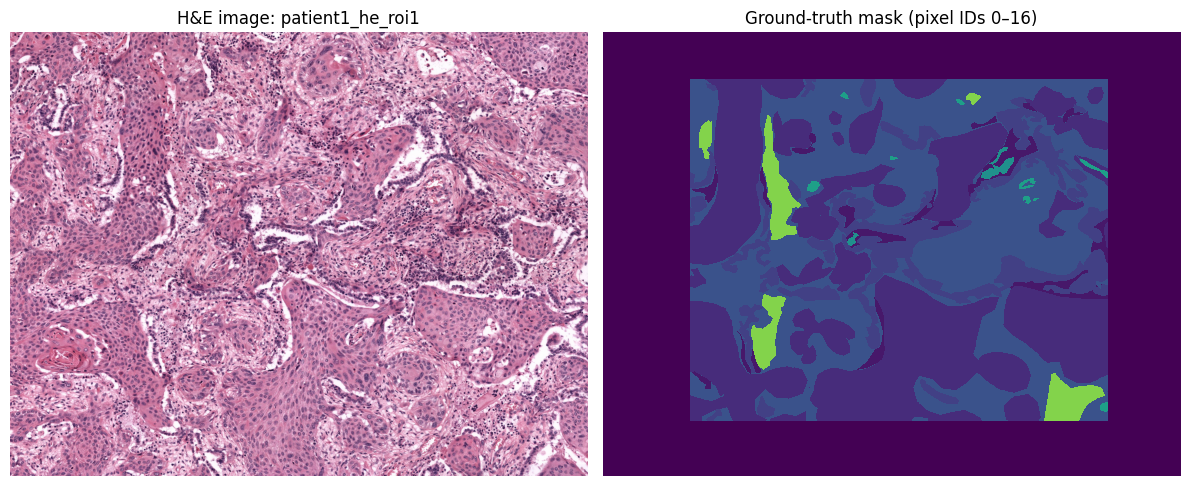

Pixel-ID counts in this ROI:
{0: 3796260, 1: 141959, 2: 1930701, 3: 571568, 4: 1866250, 8: 14560, 9: 17391, 13: 180991}


In [11]:
# Display one example image and its class-ID mask.
sample_row = he_df.iloc[0]
sample_image, sample_mask = read_image_mask(sample_row["resolved_image"], sample_row["resolved_mask"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(sample_image)
axes[0].set_title(f"H&E image: {sample_row['name']}")
axes[0].axis("off")
axes[1].imshow(sample_mask, vmin=0, vmax=16, interpolation="nearest")
axes[1].set_title("Ground-truth mask (pixel IDs 0–16)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

print("Pixel-ID counts in this ROI:")
values, counts = np.unique(sample_mask, return_counts=True)
print({int(v): int(c) for v, c in zip(values, counts)})


## 7. Create train and validation sets

**Default: patient-grouped split.** This is a conservative validation setup: all ROIs belonging to a patient are placed in either train or validation, never both. The official held-out `split == "test"` set is not used during training or model selection.

If you switch to `SPLIT_MODE = "official_fold"`, the notebook uses `validation_fold == VAL_FOLD` within the official training pool and prints whether patient IDs overlap. The official fold option is useful for reproducing the provided fold setup, but use the patient-grouped option when you need a patient-independent validation estimate.

In [12]:
from sklearn.model_selection import GroupShuffleSplit

train_pool_df = he_df[he_df["split"].astype(str).str.lower() == "train"].copy().reset_index(drop=True)
test_df = he_df[he_df["split"].astype(str).str.lower() == "test"].copy().reset_index(drop=True)

if train_pool_df.empty:
    raise ValueError("No H&E rows have split='train'. Check data_overview.csv.")

if SPLIT_MODE == "patient_grouped":
    splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
    train_idx, val_idx = next(
        splitter.split(train_pool_df, groups=train_pool_df["patient_id"].astype(str))
    )
    train_df = train_pool_df.iloc[train_idx].copy().reset_index(drop=True)
    val_df = train_pool_df.iloc[val_idx].copy().reset_index(drop=True)
elif SPLIT_MODE == "official_fold":
    train_df = train_pool_df[train_pool_df["validation_fold"].astype(str) != VAL_FOLD].copy().reset_index(drop=True)
    val_df = train_pool_df[train_pool_df["validation_fold"].astype(str) == VAL_FOLD].copy().reset_index(drop=True)
else:
    raise ValueError("SPLIT_MODE must be 'patient_grouped' or 'official_fold'.")

if train_df.empty or val_df.empty:
    raise ValueError(f"Empty split: train={len(train_df)}, validation={len(val_df)}")

train_patients = set(train_df["patient_id"].astype(str))
val_patients = set(val_df["patient_id"].astype(str))
patient_overlap = train_patients & val_patients

print(f"Split mode: {SPLIT_MODE}")
print(f"Training ROIs: {len(train_df)} | patients: {len(train_patients)}")
print(f"Validation ROIs: {len(val_df)} | patients: {len(val_patients)}")
print(f"Official held-out test ROIs (kept untouched): {len(test_df)}")
print(f"Patient overlap between train and validation: {len(patient_overlap)}")
if patient_overlap:
    print("WARNING: patient overlap exists. Do not describe this validation as patient-independent.")
else:
    print("Good: no patient IDs overlap between train and validation.")

train_records = train_df.to_dict("records")
val_records = val_df.to_dict("records")


Split mode: patient_grouped
Training ROIs: 218 | patients: 38
Validation ROIs: 51 | patients: 10
Official held-out test ROIs (kept untouched): 139
Patient overlap between train and validation: 0
Good: no patient IDs overlap between train and validation.


## 8. Install the segmentation library and confirm the GPU

Colab normally comes with PyTorch preinstalled. This cell installs the model library and checks that a CUDA GPU is visible.

In [13]:
%pip -q install -U segmentation-models-pytorch

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from functools import lru_cache

print("PyTorch:", torch.__version__)
print("Segmentation Models PyTorch:", smp.__version__ if hasattr(smp, "__version__") else "installed")
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU is active. In Colab select Runtime → Change runtime type → GPU, then rerun this cell."
    )
print("GPU:", torch.cuda.get_device_name(0))
print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.1f} GB")


PyTorch: 2.14.1+cu130
Segmentation Models PyTorch: 0.6.0
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB


## 9. Build the patch dataset

The training dataset samples random 512×512 crops from each ROI. Crop centres are chosen from annotated pixels (`mask > 0`) so that the batch is less likely to contain only unannotated context. Image and mask crops use identical coordinates. Flips and 90-degree rotations are applied jointly.

For the ImageNet-pretrained ResNet34 encoder, the notebook applies standard ImageNet mean/std normalization after scaling RGB pixels to `[0, 1]`. This differs from the authors' released nnU-Net inference preprocessing and is intentional for this U-Net baseline.

In [14]:
# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

@lru_cache(maxsize=8)
def cached_pair(image_path: str, mask_path: str):
    image, mask = read_image_mask(image_path, mask_path)
    coords = np.argwhere(mask > IGNORE_INDEX)
    # Limit cached coordinate arrays while keeping a representative random sample.
    if len(coords) > 50000:
        rng = np.random.default_rng(abs(hash((image_path, mask_path))) % (2**32))
        selected = rng.choice(len(coords), size=50000, replace=False)
        coords = coords[selected]
    return image, mask, coords


def pad_pair_to_patch(image, mask, patch_size):
    h, w = mask.shape
    pad_h = max(0, patch_size - h)
    pad_w = max(0, patch_size - w)
    if pad_h or pad_w:
        mode = "reflect" if h > 1 and w > 1 else "edge"
        image = np.pad(image, ((0, pad_h), (0, pad_w), (0, 0)), mode=mode)
        mask = np.pad(mask, ((0, pad_h), (0, pad_w)), mode="constant", constant_values=IGNORE_INDEX)
    return image, mask


def image_to_tensor(image):
    x = image.astype(np.float32) / 255.0
    if USE_IMAGENET_NORMALIZATION:
        x = (x - IMAGENET_MEAN) / IMAGENET_STD
    x = np.ascontiguousarray(x.transpose(2, 0, 1))
    return torch.from_numpy(x).float()


class IgnitePatchDataset(Dataset):
    def __init__(self, records, patch_size=512, patches_per_roi=2, augment=True):
        self.records = records
        self.patch_size = patch_size
        self.patches_per_roi = patches_per_roi
        self.augment = augment

    def __len__(self):
        return len(self.records) * self.patches_per_roi

    def __getitem__(self, index):
        row = self.records[index // self.patches_per_roi]
        image, mask, coords = cached_pair(row["resolved_image"], row["resolved_mask"])
        image, mask = pad_pair_to_patch(image, mask, self.patch_size)
        h, w = mask.shape

        if len(coords):
            cy, cx = coords[random.randrange(len(coords))]
            top = min(max(int(cy) - self.patch_size // 2, 0), h - self.patch_size)
            left = min(max(int(cx) - self.patch_size // 2, 0), w - self.patch_size)
        else:
            top = random.randint(0, max(0, h - self.patch_size))
            left = random.randint(0, max(0, w - self.patch_size))

        img_patch = image[top:top + self.patch_size, left:left + self.patch_size].copy()
        mask_patch = mask[top:top + self.patch_size, left:left + self.patch_size].copy()

        if self.augment:
            if random.random() < 0.5:
                img_patch = np.fliplr(img_patch)
                mask_patch = np.fliplr(mask_patch)
            if random.random() < 0.5:
                img_patch = np.flipud(img_patch)
                mask_patch = np.flipud(mask_patch)
            k = random.randrange(4)
            if k:
                img_patch = np.rot90(img_patch, k)
                mask_patch = np.rot90(mask_patch, k)

        x = image_to_tensor(img_patch)
        y = torch.from_numpy(np.ascontiguousarray(mask_patch)).long()
        return x, y

train_dataset = IgnitePatchDataset(
    train_records,
    patch_size=PATCH_SIZE,
    patches_per_roi=PATCHES_PER_ROI_PER_EPOCH,
    augment=True,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=(NUM_WORKERS > 0),
)

print("Patches per epoch:", len(train_dataset))
print("Batches per epoch:", len(train_loader))


Patches per epoch: 436
Batches per epoch: 109


Image batch: (4, 3, 512, 512) torch.float32
Mask batch: (4, 512, 512) torch.int64
Mask IDs in batch: [0, 1, 2, 4, 5, 8, 9, 10, 11, 13]


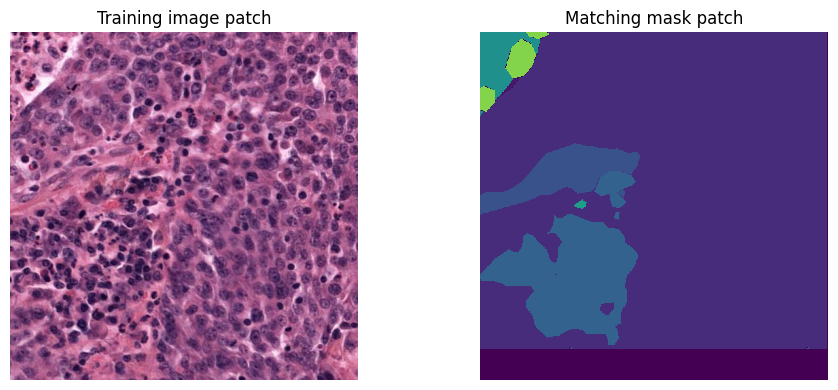

In [15]:
# Visual sanity check: inspect a batch before training.
xb, yb = next(iter(train_loader))
print("Image batch:", tuple(xb.shape), xb.dtype)
print("Mask batch:", tuple(yb.shape), yb.dtype)
print("Mask IDs in batch:", torch.unique(yb).cpu().tolist())
assert xb.shape[1:] == (3, PATCH_SIZE, PATCH_SIZE)
assert yb.shape[1:] == (PATCH_SIZE, PATCH_SIZE)
assert int(yb.max()) < NUM_CLASSES

# Reverse ImageNet normalization for display.
display_img = xb[0].cpu().numpy().transpose(1, 2, 0)
if USE_IMAGENET_NORMALIZATION:
    display_img = display_img * IMAGENET_STD + IMAGENET_MEAN
display_img = np.clip(display_img, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(display_img)
axes[0].set_title("Training image patch")
axes[0].axis("off")
axes[1].imshow(yb[0].cpu().numpy(), vmin=0, vmax=16, interpolation="nearest")
axes[1].set_title("Matching mask patch")
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 10. Create the U-Net model

This baseline uses:
- U-Net decoder
- ResNet34 ImageNet-pretrained encoder
- 3 input channels (RGB)
- 17 output channels (class IDs 0–16)
- Cross-entropy loss with `ignore_index=0`

The 17th channel is retained so output channel indices match the dataset's mask IDs. Unannotated pixels are ignored in the loss.

In [16]:
device = torch.device("cuda")

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
    activation=None,
).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2
)
scaler = torch.cuda.amp.GradScaler(enabled=True)

print("Model created:", model.__class__.__name__)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model created: Unet
Trainable parameters: 24438689


/tmp/ipykernel_716/1486474067.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


## 11. Validation: tiled inference and segmentation metrics

Validation is evaluated over the full validation ROIs, one non-overlapping 512×512 tile at a time. This avoids resizing the original images and avoids holding a full 17-channel prediction tensor in RAM. Pixels with ground-truth ID `0` are excluded from the confusion matrix.

The notebook reports:
- Per-class Dice
- Mean Dice across annotated foreground classes (IDs 2–16)
- Mean Dice including the annotated background class (IDs 1–16)
- Mean IoU across foreground classes (IDs 2–16)

In [17]:
@torch.inference_mode()
def evaluate_model(model, records, patch_size=512):
    model.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

    for row in tqdm(records, desc="Validation ROIs", leave=False):
        image, mask, _ = cached_pair(row["resolved_image"], row["resolved_mask"])
        h, w = mask.shape
        pad_h = (patch_size - h % patch_size) % patch_size
        pad_w = (patch_size - w % patch_size) % patch_size
        if pad_h or pad_w:
            mode = "reflect" if h > 1 and w > 1 else "edge"
            image_eval = np.pad(image, ((0, pad_h), (0, pad_w), (0, 0)), mode=mode)
            mask_eval = np.pad(mask, ((0, pad_h), (0, pad_w)), mode="constant", constant_values=IGNORE_INDEX)
        else:
            image_eval, mask_eval = image, mask

        H, W = mask_eval.shape
        for top in range(0, H, patch_size):
            for left in range(0, W, patch_size):
                img_patch = image_eval[top:top + patch_size, left:left + patch_size]
                gt_patch = mask_eval[top:top + patch_size, left:left + patch_size]
                x = image_to_tensor(img_patch).unsqueeze(0).to(device, non_blocking=True)
                with torch.cuda.amp.autocast(enabled=True):
                    logits = model(x)
                pred = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)

                valid = gt_patch > IGNORE_INDEX
                if valid.any():
                    encoded = gt_patch[valid].astype(np.int64) * NUM_CLASSES + pred[valid].astype(np.int64)
                    cm += np.bincount(
                        encoded, minlength=NUM_CLASSES * NUM_CLASSES
                    ).reshape(NUM_CLASSES, NUM_CLASSES)

    per_class = {}
    dice_values_all = []
    dice_values_fg = []
    iou_values_fg = []
    for class_id in range(1, NUM_CLASSES):
        tp = cm[class_id, class_id]
        fp = cm[:, class_id].sum() - tp
        fn = cm[class_id, :].sum() - tp
        dice_den = 2 * tp + fp + fn
        iou_den = tp + fp + fn
        dice = float(2 * tp / dice_den) if dice_den > 0 else float("nan")
        iou = float(tp / iou_den) if iou_den > 0 else float("nan")
        per_class[class_id] = {"class": id_to_label[class_id], "dice": dice, "iou": iou, "support": int(cm[class_id, :].sum())}
        if np.isfinite(dice):
            dice_values_all.append(dice)
            if class_id >= 2:
                dice_values_fg.append(dice)
        if class_id >= 2 and np.isfinite(iou):
            iou_values_fg.append(iou)

    metrics = {
        "mean_dice_all_annotated": float(np.mean(dice_values_all)) if dice_values_all else 0.0,
        "mean_dice_foreground": float(np.mean(dice_values_fg)) if dice_values_fg else 0.0,
        "mean_iou_foreground": float(np.mean(iou_values_fg)) if iou_values_fg else 0.0,
    }
    return metrics, per_class, cm

print("Validation function ready.")


Validation function ready.


## 12. Train, validate, and save checkpoints to Google Drive

Each epoch saves:
- `last_checkpoint.pth` — model, optimizer, scheduler, scaler, epoch, best score, and training history.
- `best_model.pth` — the checkpoint with the best validation foreground mean Dice.
- `training_history.csv` — loss and validation metrics per epoch.

If a free Colab session disconnects, reconnect, rerun the setup cells, set `RESUME_TRAINING = True` in the Configuration cell, and run the training cell again.

In [18]:
last_checkpoint_path = OUTPUT_DIR / "last_checkpoint.pth"
best_checkpoint_path = OUTPUT_DIR / "best_model.pth"
history_path = OUTPUT_DIR / "training_history.csv"

start_epoch = 1
best_val_dice = -1.0
history = []

if RESUME_TRAINING and last_checkpoint_path.exists():
    print("Resuming from:", last_checkpoint_path)
    checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = int(checkpoint["epoch"]) + 1
    best_val_dice = float(checkpoint.get("best_val_dice", -1.0))
    history = checkpoint.get("history", [])
    print(f"Continuing at epoch {start_epoch}; best foreground Dice so far: {best_val_dice:.4f}")
elif RESUME_TRAINING:
    print("No checkpoint found; starting from epoch 1.")

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    num_batches = 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}")

    for images, masks in progress:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        # Avoid a NaN if an unusually sampled batch contains only ignored pixels.
        if not torch.any(masks != IGNORE_INDEX):
            continue

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=True):
            logits = model(images)
            loss = criterion(logits, masks)

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss. Inspect mask values and ignored pixels.")

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += float(loss.detach().item())
        num_batches += 1
        progress.set_postfix(loss=f"{loss.item():.4f}")

    if num_batches == 0:
        raise RuntimeError("No training batches contained labelled pixels. Check masks and patch sampling.")

    average_loss = epoch_loss / num_batches
    val_metrics, per_class_dice, val_cm = evaluate_model(model, val_records, patch_size=PATCH_SIZE)
    val_score = val_metrics["mean_dice_foreground"]
    scheduler.step(val_score)

    row = {
        "epoch": epoch,
        "train_loss": average_loss,
        "val_mean_dice_foreground": val_metrics["mean_dice_foreground"],
        "val_mean_dice_all_annotated": val_metrics["mean_dice_all_annotated"],
        "val_mean_iou_foreground": val_metrics["mean_iou_foreground"],
        "learning_rate": optimizer.param_groups[0]["lr"],
    }
    history.append(row)
    pd.DataFrame(history).to_csv(history_path, index=False)

    checkpoint_to_save = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_dice": max(best_val_dice, val_score),
        "val_metrics": val_metrics,
        "per_class_dice": per_class_dice,
        "history": history,
        "num_classes": NUM_CLASSES,
        "ignore_index": IGNORE_INDEX,
        "patch_size": PATCH_SIZE,
        "split_mode": SPLIT_MODE,
        "normalization": "ImageNet mean/std" if USE_IMAGENET_NORMALIZATION else "RGB / 255",
    }

    # Save a local temporary copy first, then copy to Drive.
    local_last = Path("/content/last_checkpoint.pth")
    torch.save(checkpoint_to_save, local_last)
    shutil.copy2(local_last, last_checkpoint_path)

    if val_score > best_val_dice:
        best_val_dice = val_score
        local_best = Path("/content/best_model.pth")
        torch.save(checkpoint_to_save, local_best)
        shutil.copy2(local_best, best_checkpoint_path)
        print(f"Saved new best model: foreground mean Dice = {best_val_dice:.4f}")

    print(
        f"Epoch {epoch}: train_loss={average_loss:.4f} | "
        f"val_fg_Dice={val_metrics['mean_dice_foreground']:.4f} | "
        f"val_fg_IoU={val_metrics['mean_iou_foreground']:.4f} | "
        f"lr={optimizer.param_groups[0]['lr']:.2e}"
    )

print("\nTraining loop finished.")
print("Best checkpoint:", best_checkpoint_path)
print("Last checkpoint:", last_checkpoint_path)
print("History:", history_path)


Epoch 1/10:   0%|          | 0/109 [00:00<?, ?it/s]

/tmp/ipykernel_716/295544637.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

/tmp/ipykernel_716/1445059072.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Saved new best model: foreground mean Dice = 0.0705
Epoch 1: train_loss=2.4930 | val_fg_Dice=0.0705 | val_fg_IoU=0.0431 | lr=1.00e-04


Epoch 2/10:   0%|          | 0/109 [00:00<?, ?it/s]

... (22 outputs left out)

Epoch 9: train_loss=1.4418 | val_fg_Dice=0.1637 | val_fg_IoU=0.1140 | lr=1.00e-04


Epoch 10/10:   0%|          | 0/109 [00:00<?, ?it/s]

Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

Epoch 10: train_loss=1.3920 | val_fg_Dice=0.2119 | val_fg_IoU=0.1540 | lr=1.00e-04

Training loop finished.
Best checkpoint: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/best_model.pth
Last checkpoint: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/last_checkpoint.pth
History: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/training_history.csv


## 13. Plot the training history

A decreasing training loss and improving validation Dice are useful signs, but they do not prove the model generalizes. Inspect class-wise scores and visual predictions as well.

,epoch,train_loss,val_mean_dice_foreground,val_mean_dice_all_annotated,val_mean_iou_foreground,learning_rate
5,6,1.517511,0.137129,0.181441,0.097174,0.0001
6,7,1.515105,0.137006,0.180614,0.099179,0.0001
7,8,1.458171,0.220233,0.258977,0.154093,0.0001
8,9,1.441781,0.163736,0.204868,0.113989,0.0001
9,10,1.392033,0.211941,0.250461,0.153997,0.0001


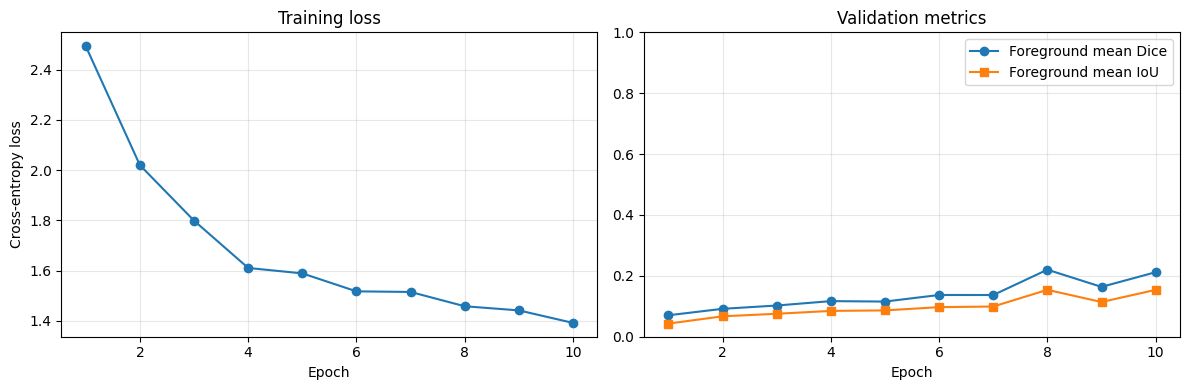

In [19]:
if history_path.exists():
    history_df = pd.read_csv(history_path)
else:
    history_df = pd.DataFrame(history)

display(history_df.tail())

if not history_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history_df["epoch"], history_df["val_mean_dice_foreground"], marker="o", label="Foreground mean Dice")
    axes[1].plot(history_df["epoch"], history_df["val_mean_iou_foreground"], marker="s", label="Foreground mean IoU")
    axes[1].set_title("Validation metrics")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


## 14. Load the best checkpoint and print class-wise validation scores

In [20]:
if not best_checkpoint_path.exists():
    raise FileNotFoundError("Best checkpoint does not exist. Run the training cell first.")

best_ckpt = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()

final_val_metrics, final_per_class, final_cm = evaluate_model(model, val_records, patch_size=PATCH_SIZE)
class_rows = []
for class_id in range(1, NUM_CLASSES):
    item = final_per_class[class_id]
    class_rows.append({
        "class_id": class_id,
        "class_name": item["class"],
        "Dice": item["dice"],
        "IoU": item["iou"],
        "ground_truth_pixels": item["support"],
    })
class_metrics_df = pd.DataFrame(class_rows)

display(class_metrics_df)
print("Validation summary:", final_val_metrics)
class_metrics_df.to_csv(OUTPUT_DIR / "validation_class_metrics.csv", index=False)
np.save(OUTPUT_DIR / "validation_confusion_matrix.npy", final_cm)


Validation ROIs:   0%|          | 0/51 [00:00<?, ?it/s]

/tmp/ipykernel_716/1445059072.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


,class_id,class_name,Dice,IoU,ground_truth_pixels
0,1,Background,0.840130,0.724331,16078512
1,2,Tumor epithelium,0.691580,0.528562,15804792
2,3,Reactive epithelium,0.000000,0.000000,1959397
3,4,Stroma,0.771914,0.628550,37793812
4,5,Inflammation,0.000024,0.000012,3573854
5,6,Alveolar tissue,0.490972,0.325356,4300206
6,7,Fatty tissue,0.000000,0.000000,550951
7,8,Necrotic tissue,0.345609,0.208904,3782464
8,9,Erythrocytes,0.000000,0.000000,2380107
9,10,Bronchial epithelium,0.000000,0.000000,272399


Validation summary: {'mean_dice_all_annotated': 0.25897694443755437, 'mean_dice_foreground': 0.2202334038350961, 'mean_iou_foreground': 0.15409337454456248}


## 15. Visualize a complete validation ROI

The next cell generates a prediction by tiling the selected ROI into 512×512 patches. It shows the original H&E image, the ground-truth mask, the predicted mask, and a prediction overlay. It does **not** use the held-out test set.

/tmp/ipykernel_716/4238769939.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


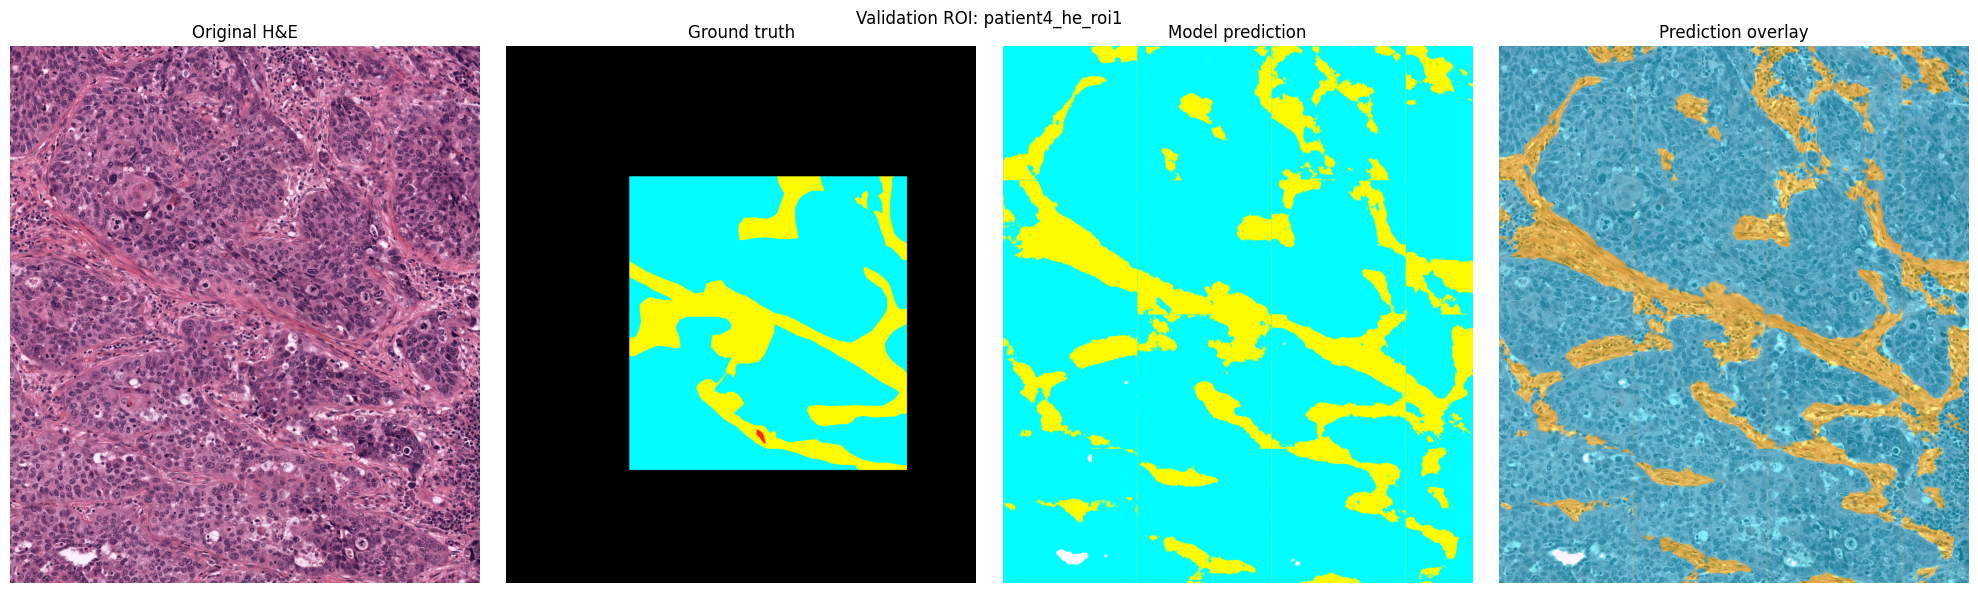

Visualized validation ROI: patient4_he_roi1


In [21]:
# A simple consistent palette for displaying the 17 class IDs.
PALETTE = np.array([
    [0, 0, 0],          # 0 Unannotated
    [255, 255, 255],    # 1 Background
    [0, 253, 255],      # 2 Tumor epithelium
    [0, 249, 0],        # 3 Reactive epithelium
    [255, 251, 0],      # 4 Stroma
    [255, 147, 0],      # 5 Inflammation
    [255, 47, 146],     # 6 Alveolar tissue
    [148, 55, 255],     # 7 Fatty tissue
    [1, 25, 147],       # 8 Necrotic tissue
    [255, 38, 0],       # 9 Erythrocytes
    [0, 143, 0],        # 10 Bronchial epithelium
    [146, 144, 0],      # 11 Mucus/Plasma/Fluids
    [169, 169, 169],    # 12 Cartilage/Bone
    [83, 27, 147],      # 13 Macrophages
    [255, 126, 121],    # 14 Muscle
    [215, 131, 255],    # 15 Liver
    [148, 23, 81],      # 16 Keratinization
], dtype=np.uint8)

@torch.inference_mode()
def predict_roi(model, image, patch_size=512):
    model.eval()
    h, w = image.shape[:2]
    pred_full = np.zeros((h, w), dtype=np.uint8)
    for top in range(0, h, patch_size):
        for left in range(0, w, patch_size):
            patch = image[top:min(top + patch_size, h), left:min(left + patch_size, w)]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                pad_h, pad_w = patch_size - ph, patch_size - pw
                mode = "reflect" if ph > 1 and pw > 1 else "edge"
                patch_input = np.pad(patch, ((0, pad_h), (0, pad_w), (0, 0)), mode=mode)
            else:
                patch_input = patch
            x = image_to_tensor(patch_input).unsqueeze(0).to(device)
            with torch.cuda.amp.autocast(enabled=True):
                logits = model(x)
            pred_patch = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
            pred_full[top:top + ph, left:left + pw] = pred_patch[:ph, :pw]
    return pred_full

vis_row = val_records[0]
vis_image, vis_mask = read_image_mask(vis_row["resolved_image"], vis_row["resolved_mask"])
vis_pred = predict_roi(model, vis_image, patch_size=PATCH_SIZE)

# Convert class IDs to RGB for visualization.
gt_rgb = PALETTE[vis_mask]
pred_rgb = PALETTE[vis_pred]
overlay = (0.55 * vis_image.astype(np.float32) + 0.45 * pred_rgb.astype(np.float32)).clip(0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
axes[0].imshow(vis_image)
axes[0].set_title("Original H&E")
axes[1].imshow(gt_rgb)
axes[1].set_title("Ground truth")
axes[2].imshow(pred_rgb)
axes[2].set_title("Model prediction")
axes[3].imshow(overlay)
axes[3].set_title("Prediction overlay")
for ax in axes:
    ax.axis("off")
plt.suptitle(f"Validation ROI: {vis_row['name']}")
plt.tight_layout()
plt.show()

print("Visualized validation ROI:", vis_row["name"])


## 16. Confirm that your outputs were saved to Drive

The folder should now contain the best model, most recent checkpoint, training log, class-wise validation metrics, and confusion matrix.

In [22]:
print("Saved output files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        print(f"{p.name:36s} {p.stat().st_size / (1024**2):.2f} MB")

print("\nBest checkpoint path:", best_checkpoint_path)
print("Training history path:", history_path)


Saved output files:
best_model.pth                       279.96 MB
last_checkpoint.pth                  279.97 MB
training_history.csv                 0.00 MB
validation_class_metrics.csv         0.00 MB
validation_confusion_matrix.npy      0.00 MB

Best checkpoint path: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/best_model.pth
Training history path: /content/drive/MyDrive/IGNITE/training_outputs/ignite_he_unet_resnet34/training_history.csv


## 17. Research notes and next steps

### What you have trained
This notebook trains a **fully supervised baseline**. It uses labelled H&E images and their masks. It is not yet semi-supervised learning.

### Next experiment: simulate limited labels
After this baseline works, create experiments using only 10%, 25%, or 50% of the training patients as labelled data. The remaining training-pool images can be treated as unlabelled. Keep the validation data labelled and fixed; never use validation or test masks to create training pseudo-labels.

### Next model: Mean Teacher
A Mean Teacher model has:
- a student network trained by gradient descent;
- a teacher network updated with an exponential moving average of student weights;
- a supervised loss on labelled images;
- a consistency or confidence-filtered pseudo-label loss on unlabelled images.

Compare each semi-supervised experiment against the supervised baseline using exactly the same validation split and metrics.

### Important reporting cautions
- Do not report validation results as test results.
- Keep the official `split == "test"` ROIs untouched until model selection and development are finished.
- Report patient overlap if you use the supplied `validation_fold` split.
- Report class-wise Dice/IoU; a single pixel accuracy can hide weak performance on rare classes.
- The official dataset is licensed CC BY-NC-SA 4.0. Check its conditions and cite the dataset paper if you publish or share work based on it.

## Official references
- [IGNITE v2 dataset on Zenodo](https://zenodo.org/records/17735903)
- [Official IGNITE GitHub repository](https://github.com/DIAGNijmegen/ignite-data-toolkit)
- [Official H&E inference script](https://github.com/DIAGNijmegen/ignite-data-toolkit/blob/main/code/he_segmentation/inference.py)
- [Official H&E evaluation script](https://github.com/DIAGNijmegen/ignite-data-toolkit/blob/main/code/he_segmentation/evaluation.py)
- [Dataset paper preprint](https://arxiv.org/abs/2507.16855)

**Dataset citation:** Spronck et al. (2025), *A tissue and cell-level annotated H&E and PD-L1 histopathology image dataset in non-small cell lung cancer*, arXiv:2507.16855.